# 04 · Forecast scores, calibration and model risk

**RQ3:** Does the conclusion survive changing the loss and dependence assumptions?
The frozen benchmark has an informative ranking reversal. QLIKE remains primary;
the quadratic score is retained with paired uncertainty, rather than promoted
after seeing favorable outcomes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(rows, columns):
    print(" | ".join(columns))
    for row in rows:
        print(
            " | ".join(
                (
                    f"{row.get(c):.6g}" if isinstance(row.get(c), float) else str(row.get(c))
                    for c in columns
                )
            )
        )

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## What the scores measure

For $z=Y^2$ and positive forecast $v$,

```math
\ell_Q(v,z)=\log v+z/v,\qquad \ell_2(v,z)=v^2-2vz.
```

Paired differences are affine in $z$. If $m=\mathbb E[z\mid\mathcal F]$, expected
regrets are $\log(v/m)+m/v-1$ and $(v-m)^2$. Both target the conditional second
moment but weight misspecification differently. QLIKE is sensitive to severe
relative underprediction; quadratic loss weights cash-scale errors. A Gaussian
distribution is not needed. QLIKE uses the original positive floor; quadratic
loss uses the unfloored nonnegative forecast. See
[Patton (2011)](https://public.econ.duke.edu/~ap172/Patton_vol_proxies_JoE_2011.pdf).

In [2]:
scores = evidence["scores"]
print(json.dumps(scores["protocol"], indent=2))
paired = [
    r
    for r in scores["paired_comparisons"]
    if r["stratum"] == "pooled" and r["method"] == "spde_local"
]
table(
    paired,
    [
        "exposure",
        "loss",
        "common_count",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)

{
  "primary_loss": "qlike",
  "secondary_loss": "quadratic",
  "reference": "direct",
  "difference_sign": "method minus direct; negative favours method",
  "pnl_variance_floor_cny2": 25.0,
  "primary_bootstrap_block": 20,
  "bootstrap_replications": 1000,
  "bootstrap_seed": 20261026,
  "bootstrap_unit": "chronologically ordered scored sessions, circular moving blocks",
  "minimum_public_cell_count": 5,
  "uncertainty_scope": "conditional descriptive bootstrap with nominal 95% percentile intervals; not a model confidence interval; no model-selection or multiple-comparison correction",
  "coverage_scope": "scored-record union; attempted and issued counts require the separate forecast audit",
  "outcome_strata_scope": "ex-post realized outcomes, not past-only regime forecasts",
  "influence_scope": "post-hoc deletions; full-sample primary results remain unchanged",
  "loss_interpretation": {
    "target": "conditional second moment E[P&L squared | past], not automatically conditional v

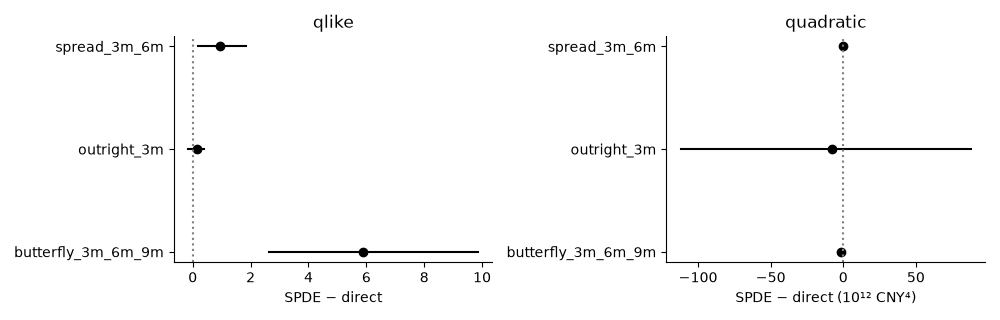

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, loss, scale in zip(axes, ["qlike", "quadratic"], [1.0, 1000000000000.0], strict=True):
    rows = [r for r in paired if r["loss"] == loss and r["available"]]
    for i, r in enumerate(rows):
        lo, hi = np.asarray(r["bootstrap_percentile_95"]) / scale
        ax.plot([lo, hi], [i, i], color="black")
        ax.plot(r["mean"] / scale, i, "o", color="black")
    ax.axvline(0, color="0.5", linestyle=":")
    ax.set_yticks(range(len(rows)), [r["exposure"] for r in rows])
    ax.set(title=loss, xlabel="SPDE − direct" + (" (10¹² CNY⁴)" if scale > 1 else ""))
fig.tight_layout()
plt.show()

## Dependence, calibration and period sensitivity

Circular moving blocks resample chronologically ordered paired scored sessions.
The number of sessions is not a Monte Carlo replication count. The percentile
ranges are descriptive and do not correct for the many explored comparisons.
Calibration bins are based on forecast risk, and realized-outcome strata are
explicitly ex post. Neither is used to tune a policy on the evaluation outcomes.

In [4]:
sensitivity = [
    r
    for r in scores["block_sensitivity"]
    if r["method"] == "spde_local" and r["exposure"] == "spread_3m_6m"
]
table(
    sensitivity,
    [
        "loss",
        "requested_block_length",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)
table(
    [
        r
        for r in scores["method_summaries"]
        if r["method"] in ("spde_local", "direct") and r["stratum"] == "year"
    ],
    ["group", "exposure", "method", "count", "mean_qlike", "risk_ratio"],
)

loss | requested_block_length | mean | bootstrap_standard_error | bootstrap_percentile_95
qlike | 5 | 0.952961 | 0.389462 | [0.27445747803463943, 1.785963182414329]
qlike | 10 | 0.952961 | 0.416853 | [0.2620298478917785, 1.8712611527292398]
qlike | 20 | 0.952961 | 0.426141 | [0.18776715756133833, 1.839482306926703]
qlike | 40 | 0.952961 | 0.442005 | [0.1735065209630078, 1.890893238855699]
quadratic | 5 | -3.90677e+11 | 9.06547e+10 | [-577082362589.7567, -225646788704.58942]
quadratic | 10 | -3.90677e+11 | 1.07776e+11 | [-622717633938.2552, -197434196919.04358]
quadratic | 20 | -3.90677e+11 | 1.21984e+11 | [-665443057264.4683, -176561001815.96085]
quadratic | 40 | -3.90677e+11 | 1.16785e+11 | [-636043402089.141, -175189953421.78455]
group | exposure | method | count | mean_qlike | risk_ratio
2024 | butterfly_3m_6m_9m | direct | 241 | 14.826 | 0.596359
2024 | butterfly_3m_6m_9m | spde_local | 241 | 18.888 | 5.60073
2025 | butterfly_3m_6m_9m | direct | 243 | 15.3049 | 0.709381
2025 | butt

exposure | forecast_variance_quintile | count | predicted_rms_cny | realized_rms_cny | risk_ratio
butterfly_3m_6m_9m | 1 | 97 | 276.131 | 829.793 | 9.03047
butterfly_3m_6m_9m | 2 | 97 | 313.17 | 1201 | 14.707
butterfly_3m_6m_9m | 3 | 96 | 338.042 | 1143.57 | 11.4442
butterfly_3m_6m_9m | 4 | 97 | 375.459 | 1006.83 | 7.191
butterfly_3m_6m_9m | 5 | 97 | 614.238 | 1071.05 | 3.04048
outright_3m | 1 | 97 | 2135.97 | 3333.31 | 2.43536
outright_3m | 2 | 97 | 2474.6 | 3457.77 | 1.95246
outright_3m | 3 | 96 | 2759.42 | 3231.94 | 1.3718
outright_3m | 4 | 97 | 3042.57 | 2382.67 | 0.613264
outright_3m | 5 | 97 | 4867.48 | 4646.7 | 0.911342
spread_3m_6m | 1 | 97 | 219.348 | 464.542 | 4.48519
spread_3m_6m | 2 | 97 | 257.032 | 496.327 | 3.72872
spread_3m_6m | 3 | 96 | 281.884 | 546.747 | 3.76211
spread_3m_6m | 4 | 97 | 316.773 | 476.294 | 2.26075
spread_3m_6m | 5 | 97 | 513.283 | 532.863 | 1.07775


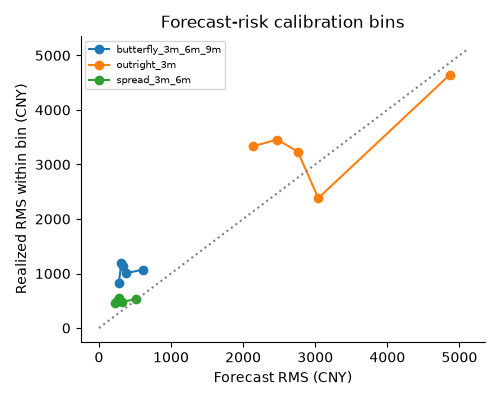

In [5]:
rows = [r for r in scores["calibration_bins"] if r["method"] == "spde_local"]
table(
    rows,
    [
        "exposure",
        "forecast_variance_quintile",
        "count",
        "predicted_rms_cny",
        "realized_rms_cny",
        "risk_ratio",
    ],
)
fig, ax = plt.subplots(figsize=(5, 4))
for exposure in sorted({r["exposure"] for r in rows}):
    selected = [r for r in rows if r["exposure"] == exposure and r["available"]]
    ax.plot(
        [r["predicted_rms_cny"] for r in selected],
        [r["realized_rms_cny"] for r in selected],
        "o-",
        label=exposure,
    )
limit = ax.get_xlim()[1]
ax.plot([0, limit], [0, limit], ":", color="0.5")
ax.set(
    xlabel="Forecast RMS (CNY)",
    ylabel="Realized RMS within bin (CNY)",
    title="Forecast-risk calibration bins",
)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Influential paired differences

The following diagnostic removes the largest 1% or 5% of absolute paired score
differences. It measures influence, not a preferred cleaned evaluation sample.
No dates or individual market outcomes are exported; small cells are suppressed.

In [6]:
table(
    [r for r in scores["score_influence"] if r["method"] == "spde_local"],
    [
        "exposure",
        "loss",
        "fraction",
        "full_mean_difference",
        "remaining_mean_difference",
        "removed_absolute_difference_share",
    ],
)
table(
    [r for r in scores["availability"] if r["method"] in ("direct", "spde_local")],
    list(scores["availability"][0].keys()),
)

exposure | loss | fraction | full_mean_difference | remaining_mean_difference | removed_absolute_difference_share
butterfly_3m_6m_9m | qlike | 0.01 | 5.88185 | 3.50357 | 0.319871
butterfly_3m_6m_9m | qlike | 0.05 | 5.88185 | 1.82687 | 0.549707
butterfly_3m_6m_9m | quadratic | 0.01 | -1.64749e+12 | -2.1423e+12 | 0.197902
butterfly_3m_6m_9m | quadratic | 0.05 | -1.64749e+12 | -9.92212e+11 | 0.515883
outright_3m | qlike | 0.01 | 0.130267 | 0.123932 | 0.244522
outright_3m | qlike | 0.05 | 0.130267 | 0.0619897 | 0.481096
outright_3m | quadratic | 0.01 | -7.44415e+12 | -9.4425e+12 | 0.337895
outright_3m | quadratic | 0.05 | -7.44415e+12 | 1.50821e+13 | 0.628849
spread_3m_6m | qlike | 0.01 | 0.952961 | 0.460469 | 0.203144
spread_3m_6m | qlike | 0.05 | 0.952961 | -0.184241 | 0.4607
spread_3m_6m | quadratic | 0.01 | -3.90677e+11 | -2.99362e+11 | 0.224991
spread_3m_6m | quadratic | 0.05 | -3.90677e+11 | -1.46996e+11 | 0.566021
exposure | method | method_count | reference_count | union_count | co

## Interpretation and next decision

The spread difference is +0.953 under primary QLIKE (bootstrap range
[0.188, 1.839]) but −0.391×10¹² CNY⁴ under quadratic loss (range
[−0.665, −0.177]×10¹²). Outright and butterfly quadratic ranges include zero.

Read score ranking, calibration and uncertainty together. Favorable quadratic
loss on one exposure does not remove a QLIKE or underprediction failure. The
matched-window experiment addresses attribution; the joint model addresses
missing risk. An uninspected confirmation period is needed for a revised policy.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/04_forecast_scores_and_model_risk.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).